In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import helper_utils

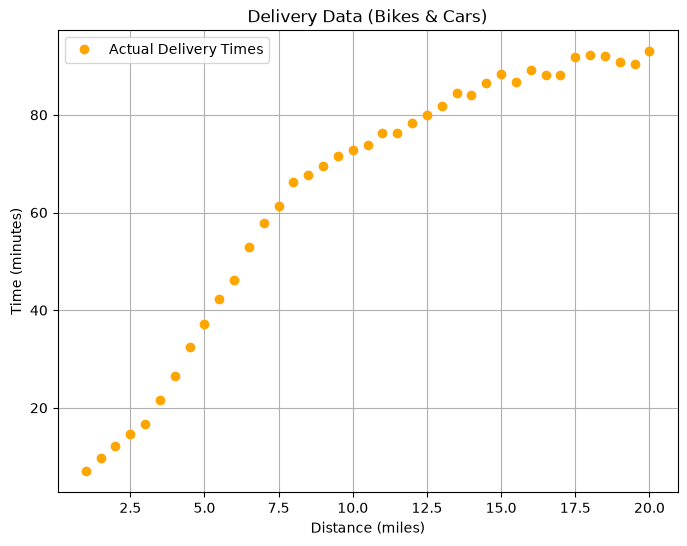

In [7]:
# Combined dataset: bikes for short distances, cars for longer ones
distances = torch.tensor([
    [1.0], [1.5], [2.0], [2.5], [3.0], [3.5], [4.0], [4.5], [5.0], [5.5],
    [6.0], [6.5], [7.0], [7.5], [8.0], [8.5], [9.0], [9.5], [10.0], [10.5],
    [11.0], [11.5], [12.0], [12.5], [13.0], [13.5], [14.0], [14.5], [15.0], [15.5],
    [16.0], [16.5], [17.0], [17.5], [18.0], [18.5], [19.0], [19.5], [20.0]
], dtype=torch.float32)

# Corresponding delivery times in minutes
times = torch.tensor([
    [6.96], [9.67], [12.11], [14.56], [16.77], [21.7], [26.52], [32.47], [37.15], [42.35],
    [46.1], [52.98], [57.76], [61.29], [66.15], [67.63], [69.45], [71.57], [72.8], [73.88],
    [76.34], [76.38], [78.34], [80.07], [81.86], [84.45], [83.98], [86.55], [88.33], [86.83],
    [89.24], [88.11], [88.16], [91.77], [92.27], [92.13], [90.73], [90.39], [92.98]
], dtype=torch.float32)

helper_utils.plot_data(distances, times)

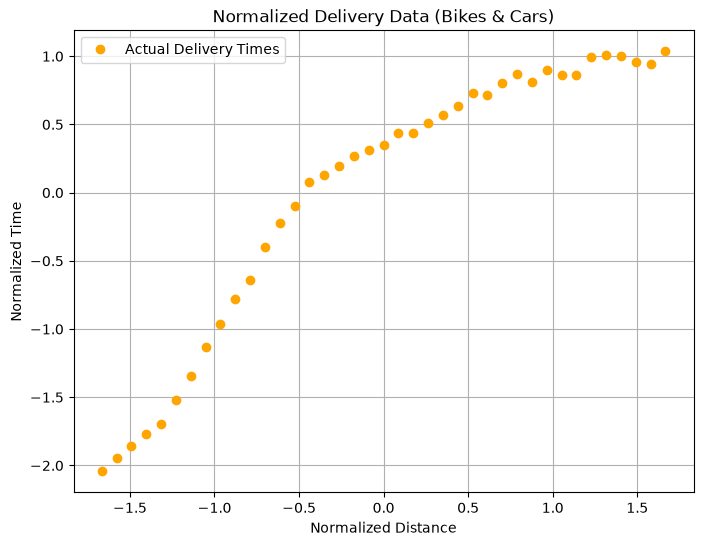

In [8]:
distances_mean=distances.mean()
times_mean=times.mean()

distances_std=distances.std()
times_std=times.std()

distances_norm=(distances-distances_mean)/distances_std
times_norm=(times-times_mean)/times_std

helper_utils.plot_data(distances_norm, times_norm, normalize=True)

In [10]:
torch.manual_seed(27)

model=nn.Sequential(
    nn.Linear(1,3),
    nn.ReLU(),
    nn.Linear(3,1)
)

In [11]:
loss_function=nn.MSELoss()
optimizer=optim.SGD(model.parameters(),lr=0.01)

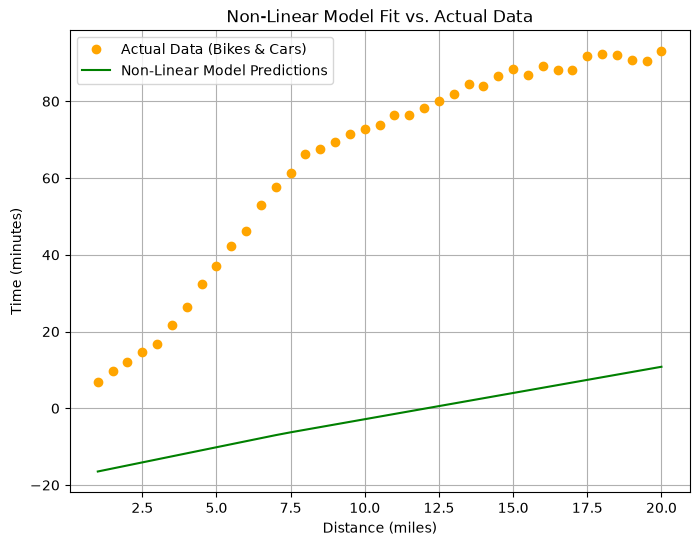

In [12]:
for epoch in range(3000):
    optimizer.zero_grad()
    predictions=model(distances_norm)
    loss=loss_function(predictions,times_norm)
    loss.backward()
    optimizer.step()

helper_utils.plot_final_fit(model, distances, times, distances_norm, times_std, times_mean)